In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

In [2]:
df = pd.read_csv("E-Commerce Order Fulfillment Dataset (50K Records).csv")
X = df[["Shipping_Cost", "Delivery_Days"]].values
y = df["Delivery_Status"].apply(lambda x: 1 if x == "Delayed" else 0).values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print(np.round(X_train[:3], 2))

[[-1.09  1.56]
 [ 0.91 -0.39]
 [-0.34  0.  ]]


In [3]:
svm_linear = SVC(kernel="linear", C=1.0, gamma="scale", random_state=42)
svm_linear.fit(X_train, y_train)

y_pred_lin = svm_linear.predict(X_test)
acc_lin = accuracy_score(y_test, y_pred_lin)
print(f"Точность линейного SVM: {acc_lin*100:.1f}%")

Точность линейного SVM: 85.9%


In [4]:
svm_rbf = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42)
svm_rbf.fit(X_train, y_train)

y_pred_rbf = svm_rbf.predict(X_test)
acc_rbf = accuracy_score(y_test, y_pred_rbf)
print(f"Точность SVM (Ядро RBF): {acc_rbf*100:.1f}%")

Точность SVM (Ядро RBF): 85.9%


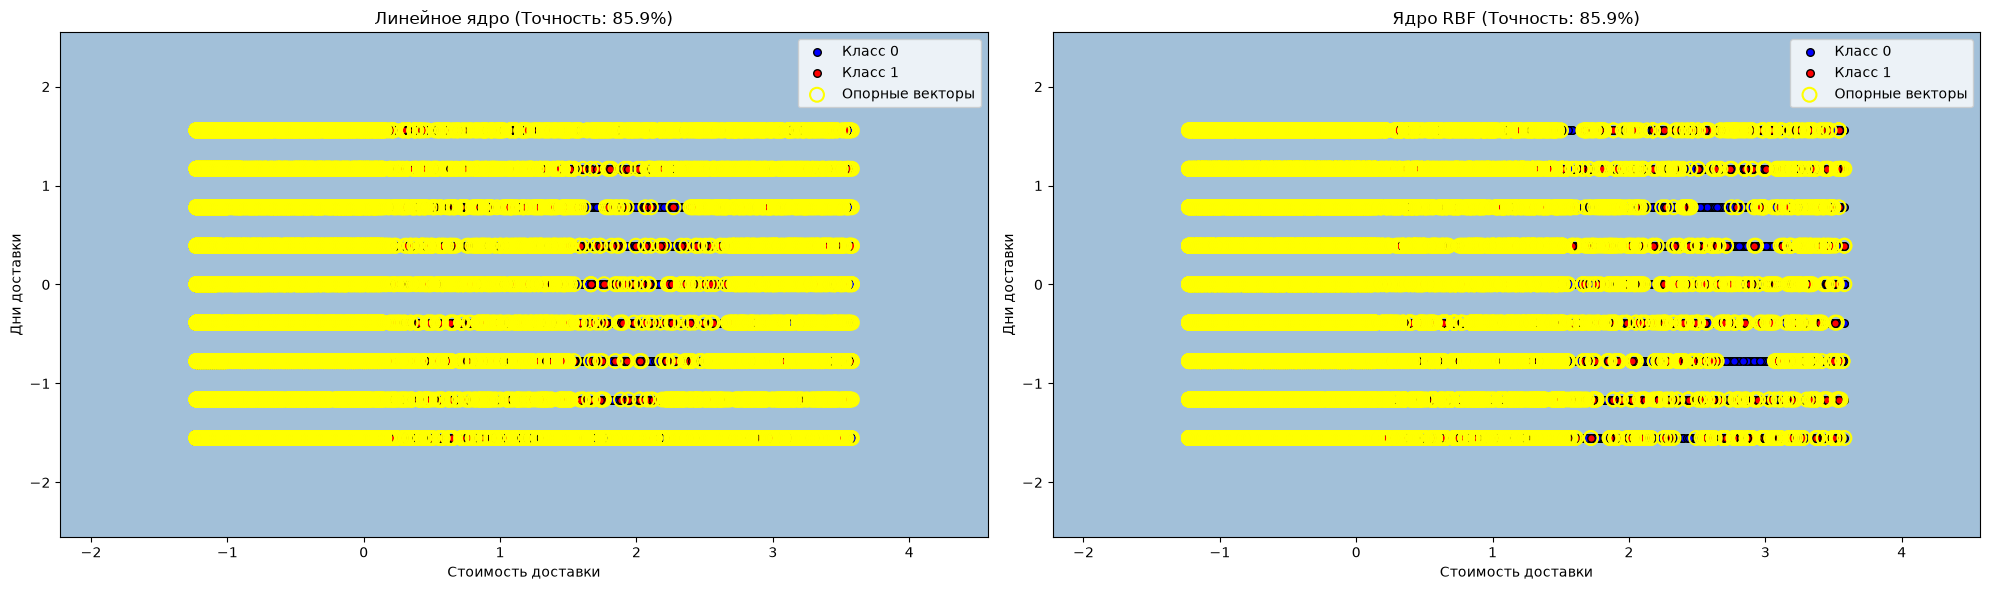

In [5]:
def plot_decision_boundary(model, ax, title):
    X_set, y_set = X_train, y_train
    X1, X2 = np.meshgrid(
        np.arange(
            start=X_set[:, 0].min() - 1, stop=X_set[:, 0].max() + 1, step=0.01
        ),
        np.arange(
            start=X_set[:, 1].min() - 1, stop=X_set[:, 1].max() + 1, step=0.01
        ),
    )
    ax.contourf(
        X1,
        X2,
        model.predict(np.array([X1.ravel(), X2.ravel()]).T).reshape(X1.shape),
        alpha=0.5,
        cmap=ListedColormap(("steelblue", "red")),
    )
    
    for i, j in enumerate(np.unique(y_set)):
        ax.scatter(
            X_set[y_set == j, 0],
            X_set[y_set == j, 1],
            color=ListedColormap(("blue", "red"))(i),
            label=f"Класс {j}",
            edgecolors="k",
            s=30,
        )
        
    ax.scatter(
        model.support_vectors_[:, 0],
        model.support_vectors_[:, 1],
        facecolors="none",
        edgecolors="yellow",
        s=100,
        linewidth=1.5,
        label="Опорные векторы",
    )
    
    ax.set_title(title)
    ax.set_xlabel("Стоимость доставки")
    ax.set_ylabel("Дни доставки")
    ax.legend()

fig, axes = plt.subplots(1, 2, figsize=(20, 6))

plot_decision_boundary(
    svm_linear, axes[0], f"Линейное ядро (Точность: {acc_lin*100:.1f}%)"
)
plot_decision_boundary(svm_rbf, axes[1], f"Ядро RBF (Точность: {acc_rbf*100:.1f}%)")

plt.tight_layout()
plt.show()